# Results for Final Evaluation on Test Split

## Setup

In [19]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

COLORS = {
    "RANDOM_SAMPLING": "#333333",
    "COARSE_UNCERTAINTY_MEASURE": "#E69F00",
    "COARSE_ENTROPY_MEASURE": "#D55E00",
    "FINE_UNCERTAINTY_MEASURE": "#56B4E9",
    "FINE_ENTROPY_MEASURE": "#0072B2",
    "GROUPED_FINE_ENTROPY": "#009E73",
    "WEIGHTED_UNCERTAINTY_MEASURE": "#CC79A7",
    "WEIGHTED_ENTROPY_MEASURE": "#7B3294",
}
LABELS = dict(zip(COLORS, [
    "Random Sampling (Baseline)", "Coarse UM", "Coarse EM", "Fine UM",
    "Fine EM", "Grouped Fine EM", "Weighted UM", "Weighted EM",
]))
GRANULARITIES = ["G_high", "G_mid", "G_low"]
TITLES = [r"$G_{\mathrm{high}}$", r"$G_{\mathrm{mid}}$", r"$G_{\mathrm{low}}$"]
METRICS = {"test_f1_event": "Mean F1 Event",
           "test_f1_element": "Mean F1 Element", "test_edit": "Edit Score"}
CLASS_AGNOSTIC = "test_f1_class_agnostic"
EXPECTED_ROUNDS = set(range(10))
# Sample SD across seeds; undefined for a single seed (no band is drawn).
SD_DDOF = 1
plt.rcParams.update({
    "figure.dpi": 150, "font.size": 11,
    "axes.titlesize": 13, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.18, "axes.axisbelow": True,
    "lines.linewidth": 1.4, "pdf.fonttype": 42, "ps.fonttype": 42,
})
relative = Path("experiments/4_active_learning_runs")
EXPERIMENT_DIR = next((base / relative for base in [Path.cwd(), *Path.cwd().parents]
                       if (base / relative).is_dir()), None)
if EXPERIMENT_DIR is None:
    raise FileNotFoundError("Run this notebook from inside the alpes repository.")
RUNS_DIR = EXPERIMENT_DIR / "runs"
if not RUNS_DIR.is_dir():
    RUNS_DIR = EXPERIMENT_DIR


def read_json(path):
    with path.open() as stream:
        return json.load(stream)


def load_results(runs_dir):
    records, inventory = [], []
    for config_path in sorted(runs_dir.glob("*/config.json")):
        config = read_json(config_path)
        run_dir = config_path.parent
        strategy = config["query_strategy"]
        if strategy not in COLORS:
            print(f"Skipping unknown strategy: {run_dir.name}")
            continue
        total = config["total_training_frames"]
        if total <= 0:
            raise ValueError(f"Invalid training frame count: {run_dir}")
        history_path = run_dir / "history.json"
        history = {int(row["round"]): row for row in read_json(history_path)} if history_path.exists() else {}
        loaded = set()
        for round_number in sorted(EXPECTED_ROUNDS):
            round_dir = run_dir / f"round_{round_number:03d}"
            result_path = round_dir / "test_results.json"
            if not result_path.exists():
                continue
            try:
                results = read_json(result_path)
                # Frame counts preserve the true annotation budget without rounding.
                frames = history.get(round_number, {}).get("labeled_pool_frames")
                if frames is None:
                    frames = sum(item["num_frames"] for item in read_json(round_dir / "labeled_train.json"))
                if not 0 < frames <= total:
                    raise ValueError("Labeled frame count is outside the training pool")
                row = {"run": run_dir.name, "seed": config["seed"], "strategy": strategy,
                       "round": round_number, "budget_pct": 100.0 * frames / total}
                for granularity in GRANULARITIES:
                    for metric in METRICS:
                        value = float(results[granularity][metric])
                        upper = 100 if metric == "test_edit" else 1
                        if not np.isfinite(value) or not 0 <= value <= upper:
                            raise ValueError(f"Invalid {granularity}/{metric}: {value}")
                        row[f"{granularity}/{metric}"] = value
                value = float(results.get(CLASS_AGNOSTIC, results["G_high"].get(CLASS_AGNOSTIC)))
                if not np.isfinite(value) or not 0 <= value <= 1:
                    raise ValueError("Invalid class-agnostic F1")
                row[CLASS_AGNOSTIC] = value
            except (OSError, ValueError, KeyError, TypeError) as exc:
                print(f"Skipping {run_dir.name}/{round_dir.name}: {exc}")
                continue
            records.append(row)
            loaded.add(round_number)
        missing = sorted(EXPECTED_ROUNDS - loaded)
        inventory.append({"run": run_dir.name, "strategy": strategy, "seed": config["seed"],
                          "loaded_rounds": len(loaded), "complete": not missing,
                          "missing_rounds": missing})
        if missing:
            print(f"{run_dir.name}: missing/unusable AL rounds {missing}")
    rounds = pd.DataFrame(records)
    inventory = pd.DataFrame(inventory)
    if rounds.empty:
        raise ValueError(f"No usable test results found in {runs_dir}")
    if inventory.duplicated(["strategy", "seed"]).any():
        raise ValueError("Multiple runs for a strategy/seed; select one configuration before aggregating.")
    for run, curve in rounds.groupby("run"):
        if not np.all(np.diff(curve.sort_values("round")["budget_pct"]) > 0):
            raise ValueError(f"Annotation budgets must increase strictly: {run}")
    print(f"Loaded {rounds['run'].nunique()} / {len(inventory)} runs, {len(rounds)} rounds; "
          f"{inventory['complete'].sum()} complete runs. Round numbers are zero-based (0–9).")
    return rounds, inventory


rounds, inventory = load_results(RUNS_DIR)
coverage = rounds.groupby(["strategy", "round"])["seed"].nunique().unstack(fill_value=0)
display(coverage.reindex(COLORS, fill_value=0).rename(index=LABELS).rename_axis("Seeds by AL round"))


def summarize(data, score):
    # Align seeds by acquisition round, using the unrounded mean actual budget.
    return data.groupby("round").agg(
        budget=("budget_pct", "mean"), budget_sd=("budget_pct", "std"),
        score=(score, "mean"), score_sd=(score, "std"), seeds=("seed", "nunique"),
    ).reindex(range(10))  # Missing rounds remain gaps, never synthetic observations.


def plot_curve(ax, data, score, relative=False):
    for strategy, color in COLORS.items():
        selected = data.loc[data["strategy"] == strategy]
        if selected.empty:
            continue
        summary = summarize(selected, score)
        budget = summary["budget"].to_numpy()
        mean = summary["score"].to_numpy()
        sd = summary["score_sd"].to_numpy()
        style = "--" if strategy == "RANDOM_SAMPLING" else "-"
        ax.plot(budget, mean, style, color=color, marker="o", markersize=3, clip_on=False)
        ax.fill_between(budget, mean - sd, mean + sd, color=color, alpha=0.12)
    ax.set(xlim=(0, 100), xticks=np.arange(0, 101, 10))
    ax.xaxis.set_major_formatter(PercentFormatter(100))
    if relative:
        ax.yaxis.set_major_formatter(PercentFormatter(100))
        ax.axhline(100, color="0.6", linestyle=":", linewidth=1)
    if data.empty:
        ax.text(0.5, 0.5, "No eligible runs", ha="center", transform=ax.transAxes)


def finish_figure(fig, data, filename):
    present = set(data["strategy"])
    handles = [Line2D([0], [0], color=color, linestyle="--" if strategy == "RANDOM_SAMPLING" else "-",
                      label=LABELS[strategy]) for strategy, color in COLORS.items() if strategy in present]
    fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, fontsize=10)
    # Leave room for endpoint ticks, axis labels, and the shared legend.
    fig.tight_layout(pad=2.0, w_pad=2.5, h_pad=2.5, rect=(0, 0.11, 1, 0.96))
    output_dir = EXPERIMENT_DIR / "test_results_figures"
    output_dir.mkdir(parents=True, exist_ok=True)
    output_path = output_dir / filename
    fig.savefig(output_path, format="pdf", bbox_inches="tight")
    print(f"Saved {output_path}")
    plt.show()


Loaded 40 / 40 runs, 400 rounds; 40 complete runs. Round numbers are zero-based (0–9).


round,0,1,2,3,4,5,6,7,8,9
Seeds by AL round,,,,,,,,,,
Random Sampling (Baseline),5,5,5,5,5,5,5,5,5,5
Coarse UM,5,5,5,5,5,5,5,5,5,5
Coarse EM,5,5,5,5,5,5,5,5,5,5
Fine UM,5,5,5,5,5,5,5,5,5,5
Fine EM,5,5,5,5,5,5,5,5,5,5
Grouped Fine EM,5,5,5,5,5,5,5,5,5,5
Weighted UM,5,5,5,5,5,5,5,5,5,5
Weighted EM,5,5,5,5,5,5,5,5,5,5


## Learning Curves

Three metrics × three granularities. Points use the unrounded mean actual frame budget across available seeds at each round; shaded bands show ±1 sample standard deviation in performance. Missing rounds remain gaps. Seed counts are shown in the setup coverage table.

Each metric row uses the same y-axis span, with panel-specific limits centered on its curves to make strategy differences easier to see.


Saved /mnt/ssd2/zachary/alpes/experiments/4_active_learning_runs/test_results_figures/test_learning_curves.pdf


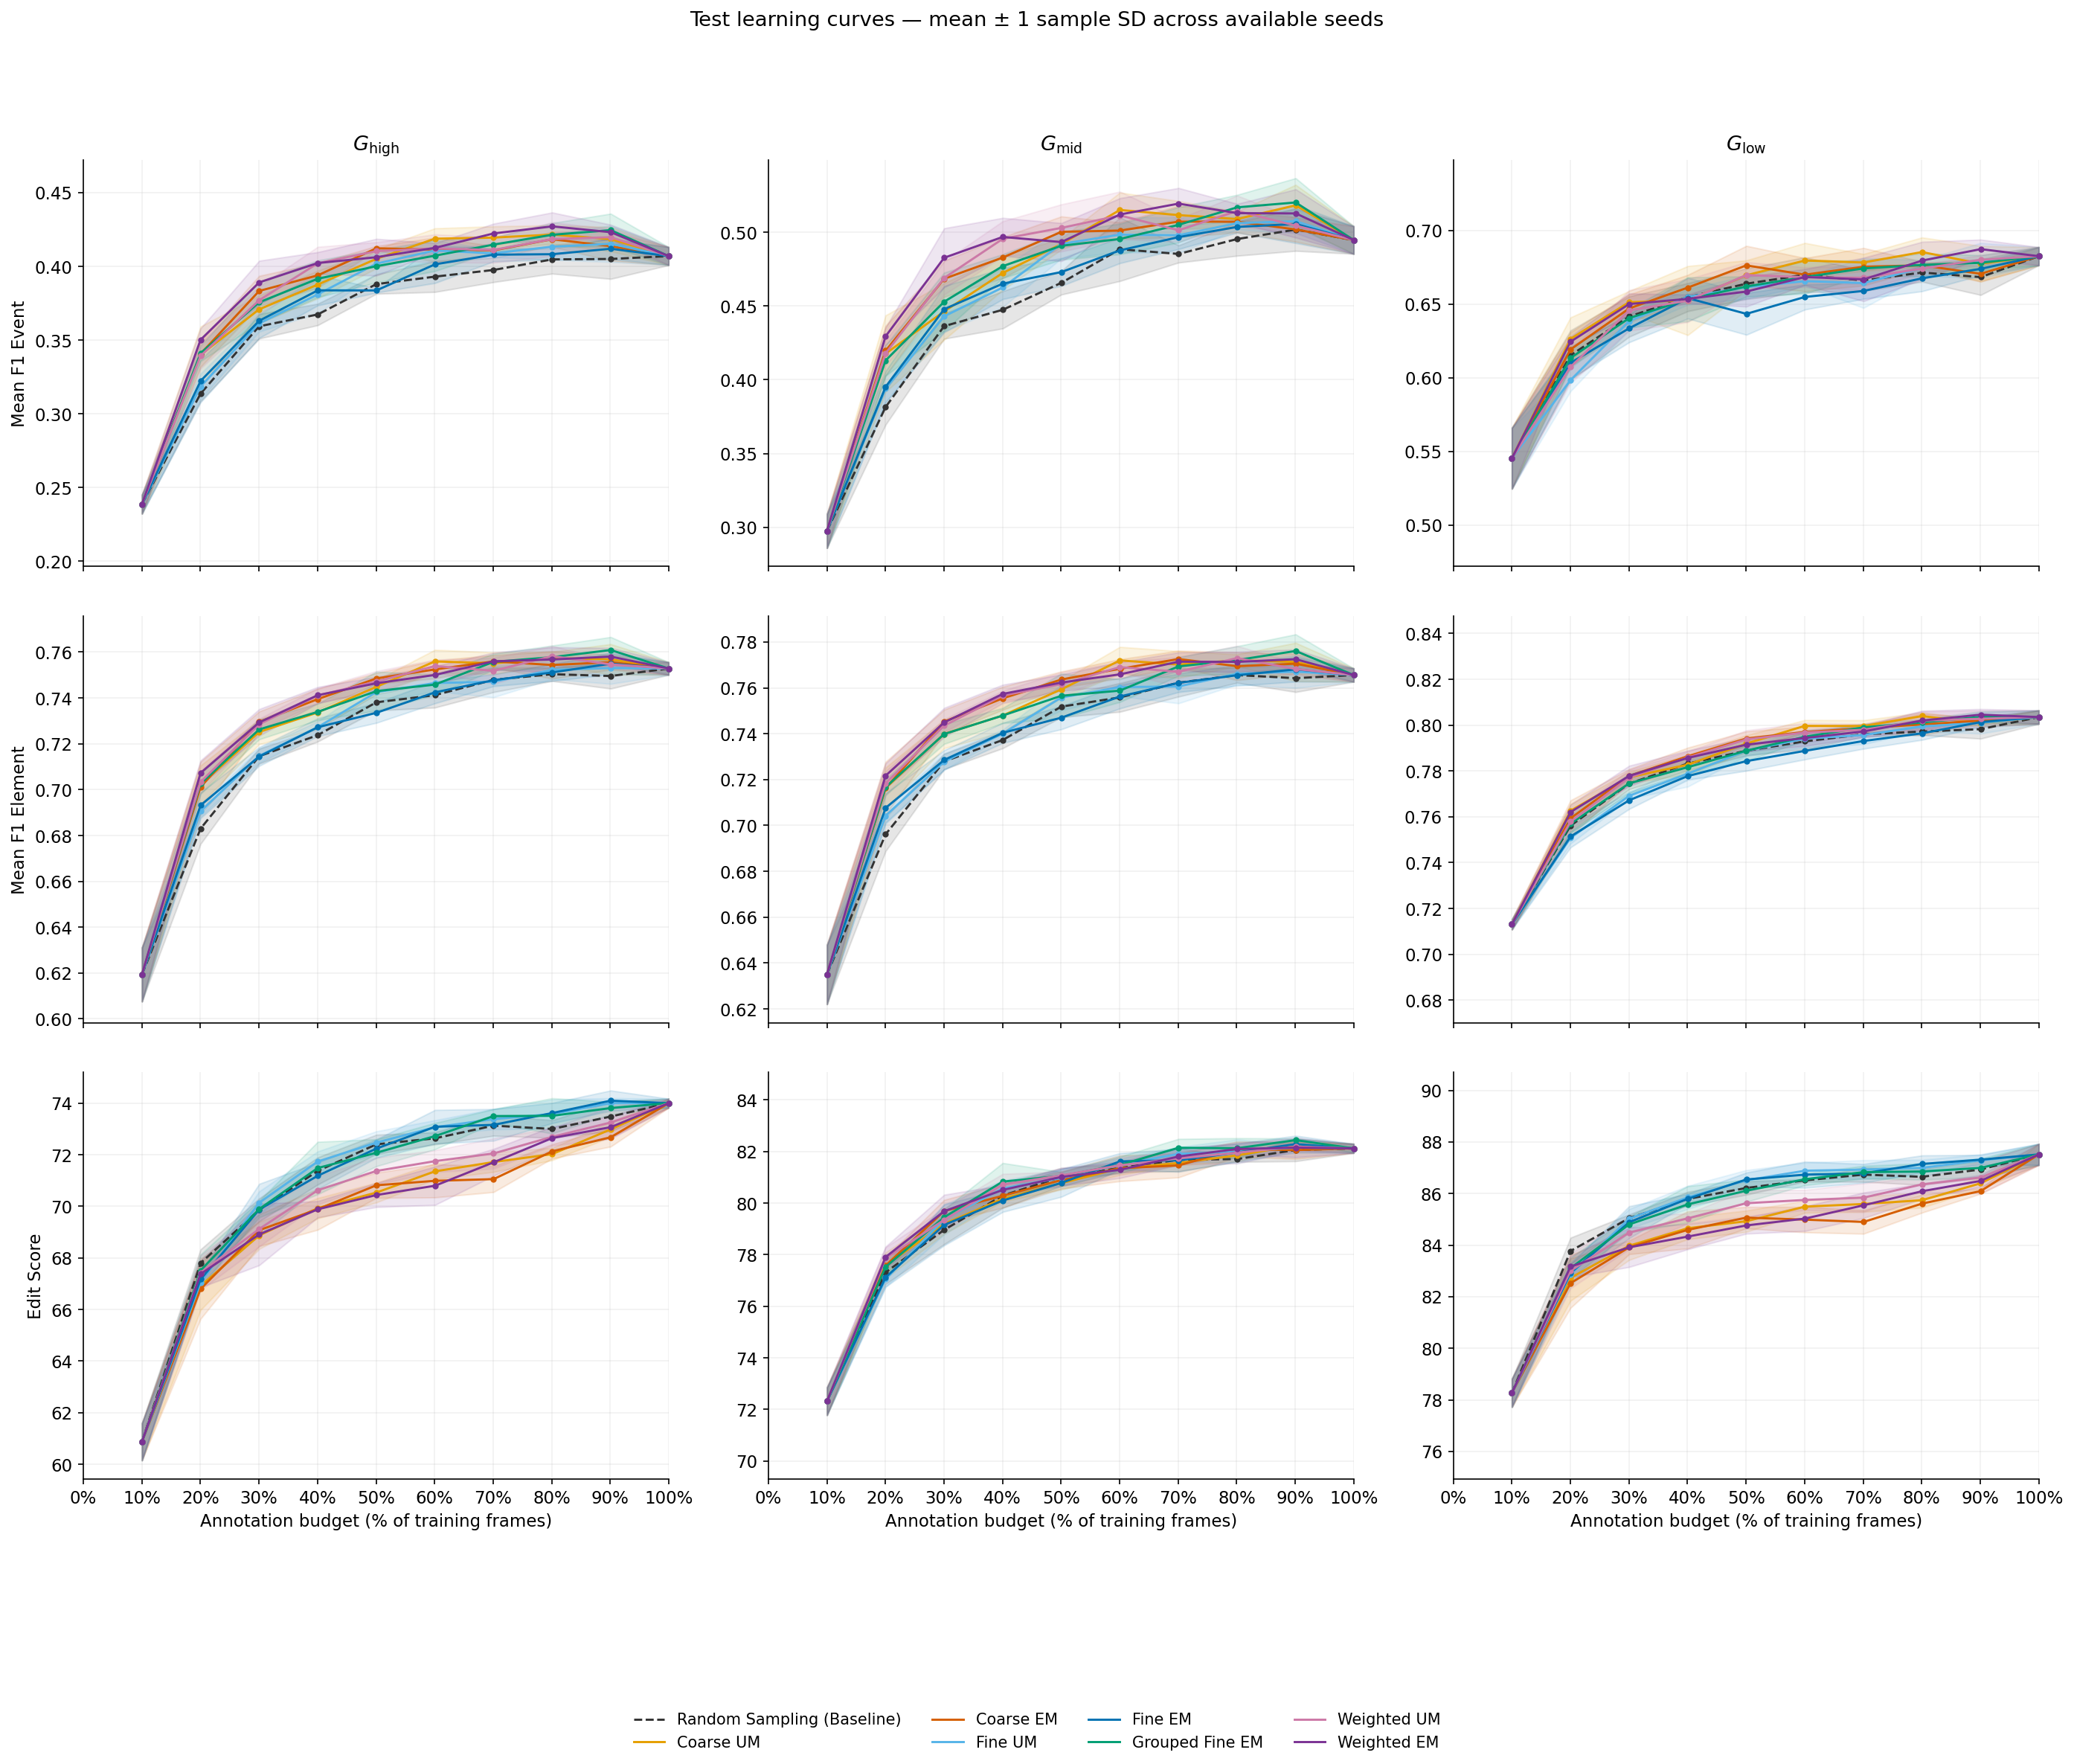

In [20]:
# Three specified metrics × three granularities. F1 remains on its native 0–1 scale.
fig, axes = plt.subplots(3, 3, figsize=(19, 16), sharex=True, sharey=False)
for row, (metric, label) in enumerate(METRICS.items()):
    for col, granularity in enumerate(GRANULARITIES):
        ax = axes[row, col]
        plot_curve(ax, rounds, f"{granularity}/{metric}")
        if row == 0:
            ax.set_title(TITLES[col])
        if col == 0:
            ax.set_ylabel(label)
        if row == 2:
            ax.set_xlabel("Annotation budget (% of training frames)")
# Keep equal units per vertical inch within each metric row, while centering
# each panel on its own data. Autoscaled limits include the SD bands.
for row_axes in axes:
    limits = [ax.get_ylim() for ax in row_axes]
    span = max(upper - lower for lower, upper in limits)
    for ax, (lower, upper) in zip(row_axes, limits):
        center = (lower + upper) / 2
        ax.set_ylim(center - span / 2, center + span / 2)

fig.suptitle("Test learning curves — mean ± 1 sample SD across available seeds")
finish_figure(fig, rounds, "test_learning_curves.pdf")


## Area Under the Learning Curve (AULC)

Compute trapezoidal AULC separately for each complete seed, using its exact budgets and normalizing by its actual first-to-last interval (approximately 10–100%). Report mean ±1 sample SD on a 0–100 scale, with relative percentage change against the random-sampling mean. A single seed has undefined SD (`N/A`).


In [21]:
def calculate_aulc(data, run_inventory, scores):
    complete_runs = run_inventory.loc[run_inventory["complete"], "run"]
    records = []
    for run, curve in data.loc[data["run"].isin(complete_runs)].groupby("run"):
        curve = curve.sort_values("budget_pct")
        budgets = curve["budget_pct"].to_numpy()
        if set(curve["round"]) != EXPECTED_ROUNDS or not np.isclose(budgets[-1], 100):
            raise ValueError(f"Complete AULC run must contain rounds 0–9 and reach 100%: {run}")
        record = {"run": run, "strategy": curve["strategy"].iloc[0], "seed": curve["seed"].iloc[0]}
        for score in scores:
            values = curve[score].to_numpy()
            # Edit score is already 0–100; F1 must be scaled by 100.
            scale = 1 if score.endswith("/test_edit") else 100
            area = np.sum(0.5 * (values[:-1] + values[1:]) * np.diff(budgets))
            record[score] = scale * area / (budgets[-1] - budgets[0])
        records.append(record)
    return pd.DataFrame(records, columns=["run", "strategy", "seed", *scores])


def aulc_table(aulcs, columns):
    baseline = aulcs.loc[aulcs["strategy"] == "RANDOM_SAMPLING"]
    rows = []
    for strategy, label in LABELS.items():
        selected = aulcs.loc[aulcs["strategy"] == strategy]
        row = {"Query Strategy": label}
        for score, title in columns.items():
            values = selected[score].astype(float)
            reference = baseline[score].astype(float).mean()
            if values.empty:
                row[title] = "—"
                continue
            mean, sd = values.mean(), values.std(ddof=SD_DDOF)
            sd_text = f"{sd:.2f}" if np.isfinite(sd) else "N/A"
            gain = f"{100 * (mean / reference - 1):+.2f}%" if reference > 0 else "N/A"
            row[title] = f"{mean:.2f} ± {sd_text} ({gain})"
        row["No. of Seeds"] = selected["seed"].nunique()
        rows.append(row)
    return pd.DataFrame(rows).set_index("Query Strategy")


score_columns = [f"{g}/{m}" for g in GRANULARITIES for m in METRICS] + [CLASS_AGNOSTIC]
aulcs = calculate_aulc(rounds, inventory, score_columns)
print("AULC: complete runs only; normalized over each run's actual first-to-last budget interval.")
print("Cells: mean ± sample SD (relative increase over random-sampling mean); N/A SD means one seed.")
aulc_tables = {}
for metric, label in METRICS.items():
    display(Markdown(f"### {label}"))
    table = aulc_table(aulcs, {f"{g}/{metric}": title for g, title in zip(GRANULARITIES, TITLES)})
    aulc_tables[metric] = table
    display(table)


AULC: complete runs only; normalized over each run's actual first-to-last budget interval.
Cells: mean ± sample SD (relative increase over random-sampling mean); N/A SD means one seed.


### Mean F1 Event

,$G_{\mathrm{high}}$,$G_{\mathrm{mid}}$,$G_{\mathrm{low}}$,No. of Seeds
Query Strategy,,,,
Random Sampling (Baseline),37.23 ± 0.25 (+0.00%),45.53 ± 0.32 (+0.00%),65.16 ± 0.50 (+0.00%),5
Coarse UM,38.94 ± 0.43 (+4.58%),47.54 ± 0.70 (+4.41%),65.93 ± 0.41 (+1.18%),5
Coarse EM,38.96 ± 0.43 (+4.65%),47.61 ± 0.53 (+4.56%),65.66 ± 0.14 (+0.77%),5
Fine UM,38.15 ± 0.30 (+2.45%),46.64 ± 0.45 (+2.44%),65.00 ± 0.32 (-0.24%),5
Fine EM,37.83 ± 0.19 (+1.60%),46.34 ± 0.35 (+1.78%),64.55 ± 0.33 (-0.93%),5
Grouped Fine EM,38.87 ± 0.28 (+4.41%),47.42 ± 0.50 (+4.14%),65.33 ± 0.46 (+0.26%),5
Weighted UM,39.03 ± 0.28 (+4.83%),47.93 ± 0.17 (+5.26%),65.32 ± 0.59 (+0.25%),5
Weighted EM,39.50 ± 0.33 (+6.10%),48.40 ± 0.57 (+6.29%),65.57 ± 0.28 (+0.64%),5


### Mean F1 Element

,$G_{\mathrm{high}}$,$G_{\mathrm{mid}}$,$G_{\mathrm{low}}$,No. of Seeds
Query Strategy,,,,
Random Sampling (Baseline),72.60 ± 0.13 (+0.00%),74.01 ± 0.15 (+0.00%),78.28 ± 0.09 (+0.00%),5
Coarse UM,73.52 ± 0.33 (+1.26%),74.99 ± 0.37 (+1.32%),78.63 ± 0.14 (+0.45%),5
Coarse EM,73.59 ± 0.33 (+1.36%),75.13 ± 0.34 (+1.51%),78.60 ± 0.17 (+0.41%),5
Fine UM,72.88 ± 0.16 (+0.39%),74.24 ± 0.20 (+0.31%),78.17 ± 0.05 (-0.13%),5
Fine EM,72.78 ± 0.09 (+0.25%),74.17 ± 0.13 (+0.22%),77.98 ± 0.05 (-0.38%),5
Grouped Fine EM,73.46 ± 0.10 (+1.19%),74.86 ± 0.12 (+1.15%),78.43 ± 0.15 (+0.19%),5
Weighted UM,73.60 ± 0.05 (+1.38%),75.08 ± 0.09 (+1.45%),78.58 ± 0.08 (+0.38%),5
Weighted EM,73.67 ± 0.22 (+1.48%),75.19 ± 0.25 (+1.60%),78.59 ± 0.18 (+0.40%),5


### Edit Score

,$G_{\mathrm{high}}$,$G_{\mathrm{mid}}$,$G_{\mathrm{low}}$,No. of Seeds
Query Strategy,,,,
Random Sampling (Baseline),71.23 ± 0.07 (+0.00%),80.18 ± 0.09 (+0.00%),85.61 ± 0.08 (+0.00%),5
Coarse UM,70.19 ± 0.21 (-1.46%),80.21 ± 0.13 (+0.04%),84.71 ± 0.17 (-1.06%),5
Coarse EM,70.09 ± 0.42 (-1.60%),80.29 ± 0.22 (+0.14%),84.51 ± 0.30 (-1.29%),5
Fine UM,71.42 ± 0.14 (+0.27%),80.30 ± 0.13 (+0.16%),85.69 ± 0.14 (+0.09%),5
Fine EM,71.31 ± 0.31 (+0.12%),80.21 ± 0.24 (+0.04%),85.67 ± 0.14 (+0.06%),5
Grouped Fine EM,71.32 ± 0.24 (+0.13%),80.47 ± 0.20 (+0.37%),85.52 ± 0.14 (-0.11%),5
Weighted UM,70.63 ± 0.28 (-0.84%),80.40 ± 0.23 (+0.27%),85.06 ± 0.16 (-0.64%),5
Weighted EM,70.24 ± 0.27 (-1.38%),80.41 ± 0.14 (+0.29%),84.69 ± 0.19 (-1.08%),5


## Annotation Budget Required to Achieve Performance Target

Performance is normalized to the verified shared full-budget result for the same seed before aggregation. Points show observed rounds in acquisition order, with unrounded mean budgets and vertical ±1 sample SD bands in relative performance. Annotation budget is on the x-axis and relative performance is on the y-axis. Curves may dip when performance decreases; no monotonicity or interpolated threshold crossing is imposed.


Verified shared full-budget references for seeds [100, 200, 300, 400, 500].
Saved /mnt/ssd2/zachary/alpes/experiments/4_active_learning_runs/test_results_figures/full_budget_performance.pdf


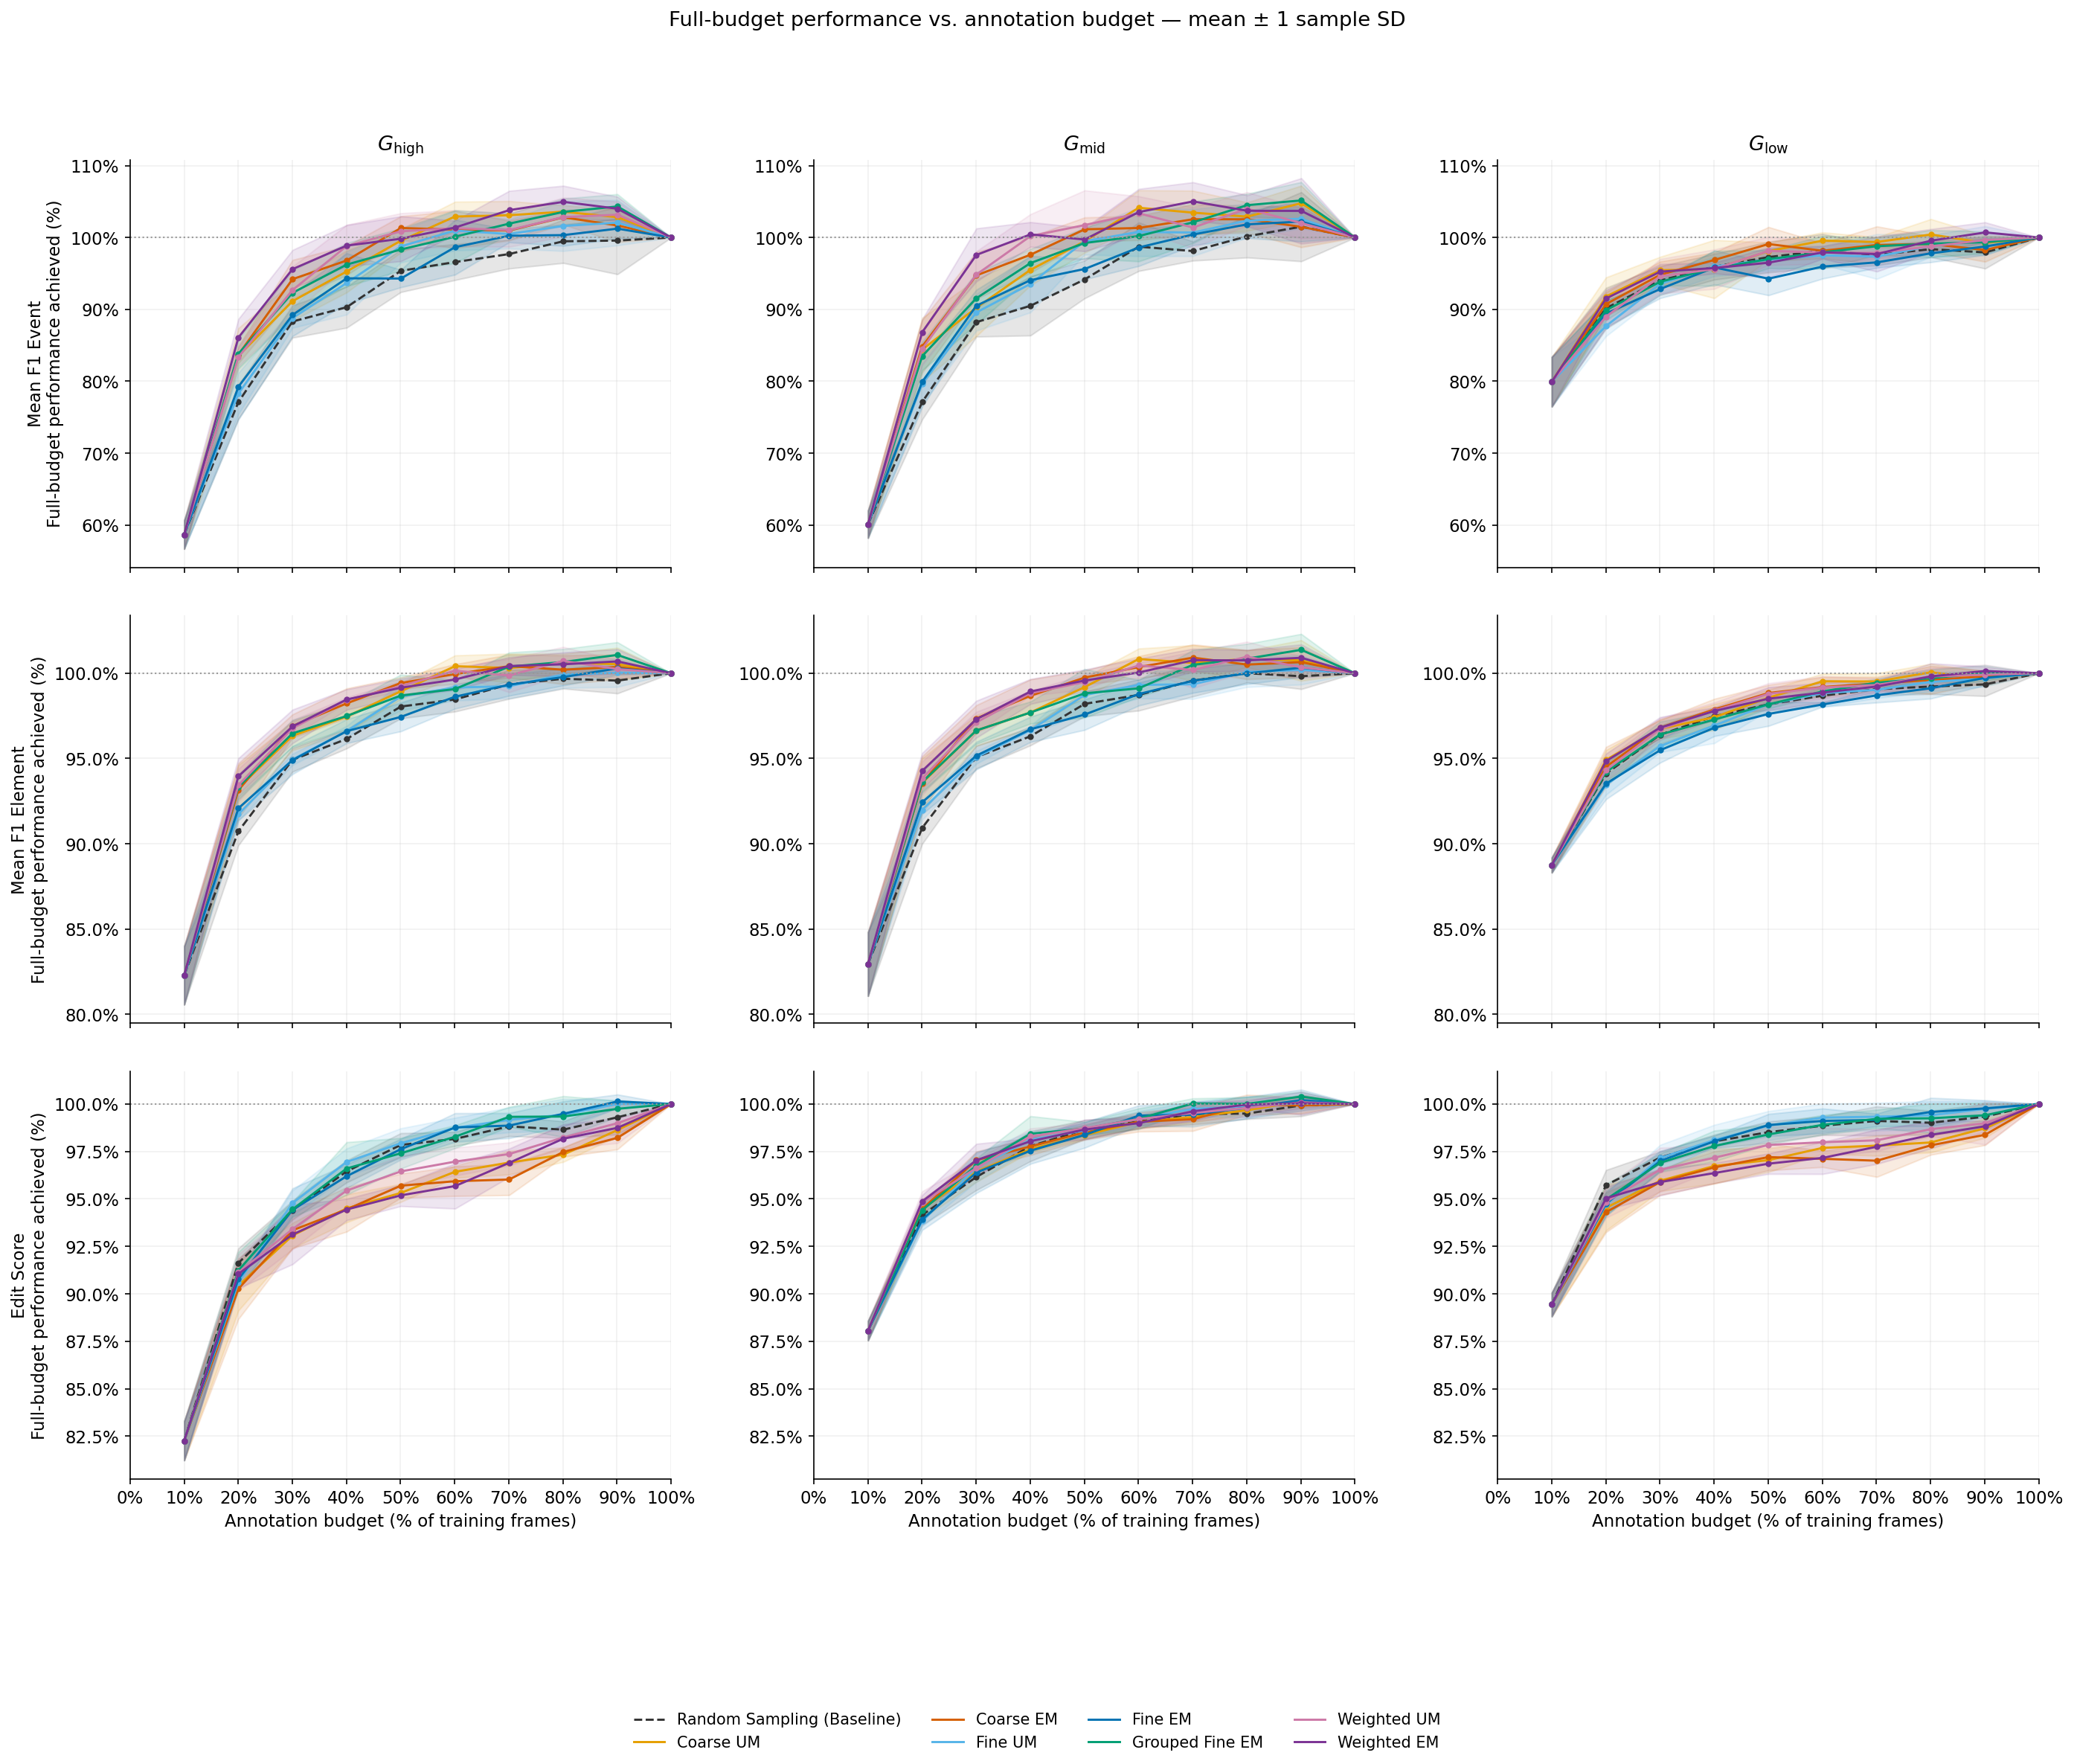

In [22]:
# All strategies must agree on full-budget performance within each seed.
# Partial runs can use the verified reference from another strategy with the same seed.
def relative_scores(data, scores):
    full = data.loc[(data["round"] == 9) & np.isclose(data["budget_pct"], 100)]
    for seed, seed_results in full.groupby("seed"):
        values = seed_results[scores].to_numpy(dtype=float)
        if not np.allclose(values, values[0], rtol=0, atol=1e-12):
            raise ValueError(f"Full-budget scores differ across strategies for seed {seed}.")
    reference = full.groupby("seed")[scores].first()
    eligible = reference.index[(reference > 0).all(axis=1)]
    relative = data.loc[data["seed"].isin(eligible)].copy()
    for score in scores:
        relative[score] = 100 * relative[score] / relative["seed"].map(reference[score])
    excluded = sorted(set(data["seed"]) - set(eligible))
    print(f"Verified shared full-budget references for seeds {list(eligible)}.")
    if excluded:
        print(f"Excluded seeds without a positive full-budget reference: {excluded}")
    return relative


relative = relative_scores(rounds, score_columns)
fig, axes = plt.subplots(3, 3, figsize=(19, 16), sharex=True, sharey="row")
for row, (metric, label) in enumerate(METRICS.items()):
    for col, granularity in enumerate(GRANULARITIES):
        ax = axes[row, col]
        plot_curve(ax, relative, f"{granularity}/{metric}", relative=True)
        ax.tick_params(axis="y", labelleft=True)
        if row == 0:
            ax.set_title(TITLES[col])
        if col == 0:
            ax.set_ylabel(f"{label}\nFull-budget performance achieved (%)")
        if row == 2:
            ax.set_xlabel("Annotation budget (% of training frames)")
fig.suptitle("Full-budget performance vs. annotation budget — mean ± 1 sample SD")
finish_figure(fig, relative, "full_budget_performance.pdf")


## Class-Agnostic PES

Saved /mnt/ssd2/zachary/alpes/experiments/4_active_learning_runs/test_results_figures/class_agnostic_pes.pdf


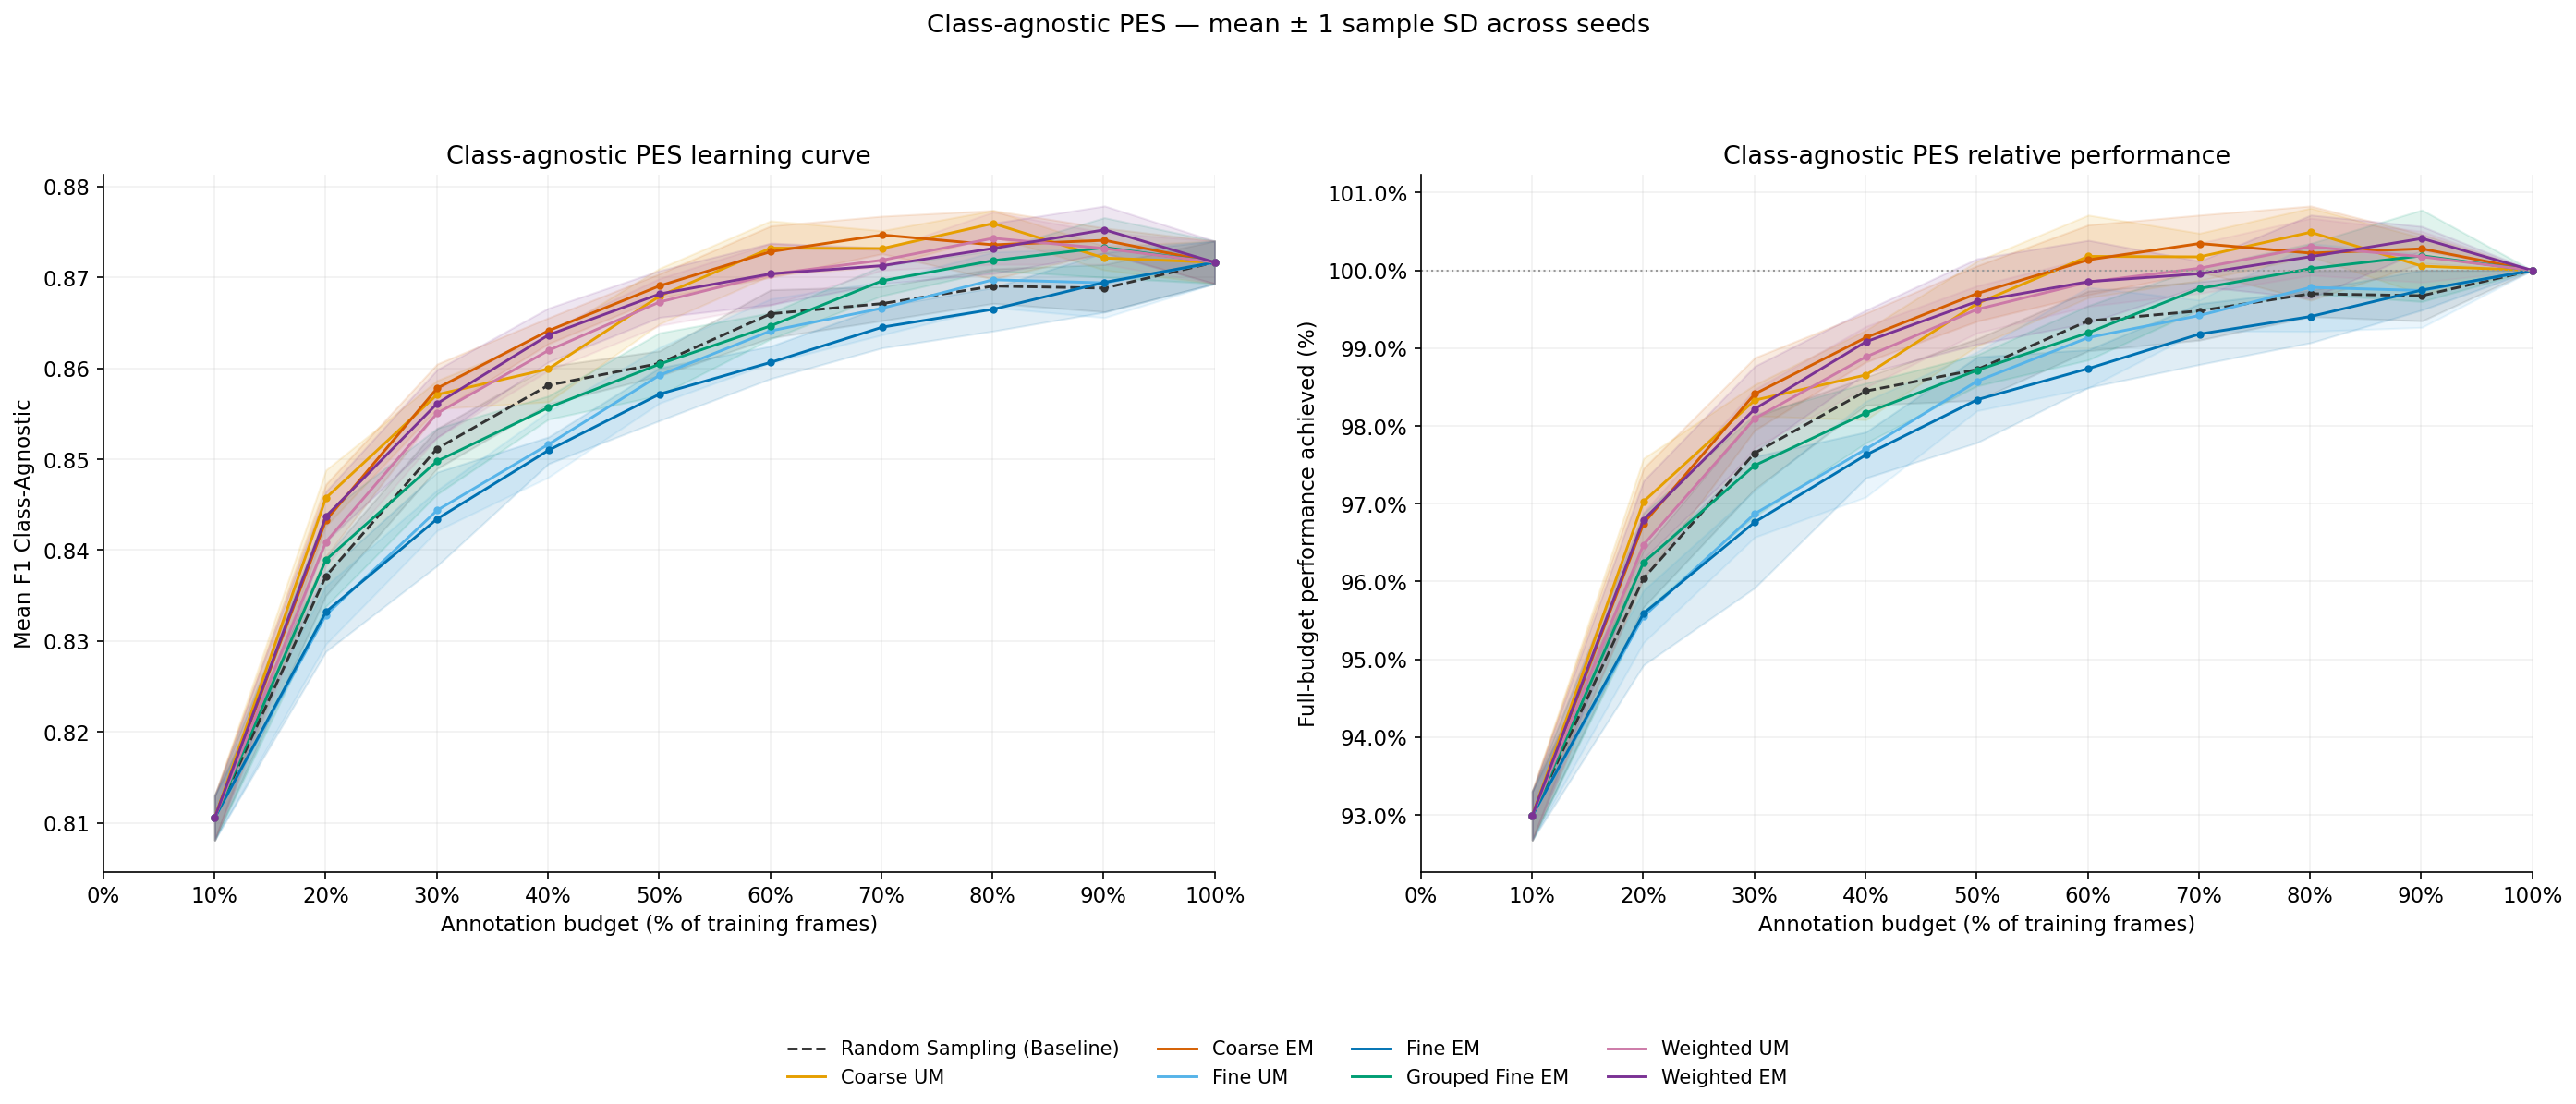

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(19, 8))
plot_curve(axes[0], rounds, CLASS_AGNOSTIC)
axes[0].set(title="Class-agnostic PES learning curve", ylabel="Mean F1 Class-Agnostic",
            xlabel="Annotation budget (% of training frames)")
plot_curve(axes[1], relative, CLASS_AGNOSTIC, relative=True)
axes[1].set(title="Class-agnostic PES relative performance", ylabel="Full-budget performance achieved (%)",
            xlabel="Annotation budget (% of training frames)")
fig.suptitle("Class-agnostic PES — mean ± 1 sample SD across seeds")
finish_figure(fig, rounds, "class_agnostic_pes.pdf")


In [24]:
class_agnostic_aulc = aulc_table(aulcs, {CLASS_AGNOSTIC: "AULC"})
display(class_agnostic_aulc)


,AULC,No. of Seeds
Query Strategy,,
Random Sampling (Baseline),85.77 ± 0.05 (+0.00%),5
Coarse UM,86.29 ± 0.08 (+0.61%),5
Coarse EM,86.34 ± 0.07 (+0.67%),5
Fine UM,85.54 ± 0.07 (-0.26%),5
Fine EM,85.41 ± 0.04 (-0.42%),5
Grouped Fine EM,85.84 ± 0.12 (+0.08%),5
Weighted UM,86.18 ± 0.08 (+0.48%),5
Weighted EM,86.25 ± 0.14 (+0.57%),5
